In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
!pip install rasterio
!pip install patchify
from patchify import patchify
import rasterio as rst

In [ ]:
im_vh='/content/drive/MyDrive/sentinel1_timeseries/s1_1vh_2018.tif'
im_vv='/content/drive/MyDrive/sentinel1_timeseries/s1_1vv_2018.tif'
im_dem='/content/drive/MyDrive/timeseries/Dem/dem_1.tif'

In [ ]:
im_vh=rst.open(im_vh).read()
im_vv=rst.open(im_vv).read()
im_dem=rst.open(im_dem).read()

In [ ]:
sent_im = np.concatenate((im_vh,im_vv,im_dem),axis=0)
sent_im_reshape=np.moveaxis(sent_im,0,-1)
sent_im_reshape.shape


(2041, 2202, 3)

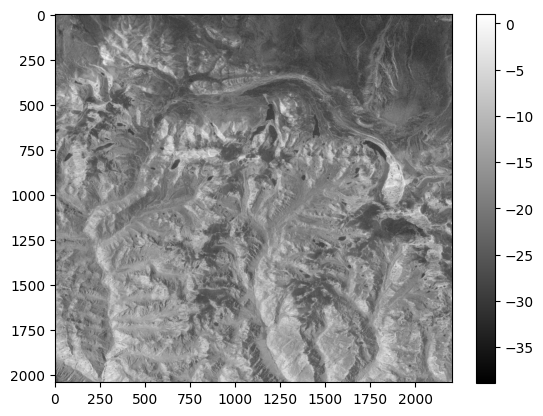

In [ ]:
plt.imshow(sent_im_reshape[:,:,0],cmap='gray')
plt.colorbar()

create patches

In [ ]:
patch_size=64
patch_sent_im_reshape = patchify(sent_im_reshape, (patch_size, patch_size, 3), step=patch_size)
print(f'image of shape: {sent_im_reshape.shape} patched into shape of : {patch_sent_im_reshape.shape}')

image of shape: (2041, 2202, 3) patched into shape of : (31, 34, 1, 64, 64, 3)


In [ ]:
ctr = 0
for i in range(patch_sent_im_reshape.shape[0]):
    for j in range(patch_sent_im_reshape.shape[1]):
        if patch_sent_im_reshape[i, j, :, :].sum():
            np.save(f'/content/drive/MyDrive/timeseries/2018/unfil_2018/im_4/patch_{ctr}.npy', patch_sent_im_reshape[i, j, :, :])
            ctr += 1
print(f'Total patches saved: {ctr}')

Total patches saved: 1054


filteration


In [ ]:
unfil_dir = '/content/drive/MyDrive/timeseries/2015/unfil/im_1'
fil_dir = '/content/drive/MyDrive/ritu_trials/filt_patches/bin/im1/res1'
output_dir = '/content/drive/MyDrive/timeseries/2018/filtered_2018/im_4'

os.makedirs(output_dir, exist_ok=True)
filtered_patches = {os.path.basename(f) for f in os.listdir(fil_dir)}
saved_patch_count = 0

# Filter and save matching patches from unfil
for patch in os.listdir(unfil_dir):
    if os.path.basename(patch) in filtered_patches:
        patch_data = np.load(os.path.join(unfil_dir, patch))
        np.save(os.path.join(output_dir, patch), patch_data)
        saved_patch_count += 1
print(f"Total patches saved: {saved_patch_count}")

Total patches saved: 124


In [ ]:
unfil_dir = '/content/drive/MyDrive/timeseries/2015/unfil/im_1'
fil_dir = '/content/drive/MyDrive/ritu_trials/filt_patches/bin/im1/res1'
output_dir = '/content/drive/MyDrive/TIMESERIES_filtered_updated/2015/im_1'

os.makedirs(output_dir, exist_ok=True)
filtered_patches = {os.path.basename(f) for f in os.listdir(fil_dir)}


# Filter and save matching patches from unfil
for patch in os.listdir(unfil_dir):
    if os.path.basename(patch) in filtered_patches:
        patch_data = np.load(os.path.join(unfil_dir, patch))
        np.save(os.path.join(output_dir, patch), patch_data)


In [ ]:
chk='/content/drive/MyDrive/TIMESERIES_filtered_updated/2015/im_1'
tst = len(os.listdir(chk))
print(tst)

90


In [ ]:
import os
import numpy as np
import shutil

# Paths
input_dir = "/content/drive/MyDrive/rashid_trials/fil/bin/im1/res1"
output_dir = "/content/drive/MyDrive/summit"

# Create output folder if not exists
os.makedirs(output_dir, exist_ok=True)

saved_count = 0

# Loop through all npy files
for file in os.listdir(input_dir):
    if file.endswith(".npy"):
        file_path = os.path.join(input_dir, file)

        # Load binary patch
        patch = np.load(file_path)

        # Check if glacier lake exists (at least one '1')
        if np.any(patch == 1):
            shutil.copy(file_path, os.path.join(output_dir, file))
            saved_count += 1

print(f"✅ Total glacier-lake patches saved: {saved_count}")


✅ Total glacier-lake patches saved: 0


In [ ]:
import os
import numpy as np
import shutil

# Paths
input_dir = "//content/drive/MyDrive/rashid_trials/fil/bin/im1/res1"
output_dir = "/content/drive/MyDrive/summit"

# Create output directory if it does not exist
os.makedirs(output_dir, exist_ok=True)

saved_count = 0

# Loop through all patch files
for file in os.listdir(input_dir):
    if file.endswith(".npy"):
        file_path = os.path.join(input_dir, file)

        # Load binary patch (64x64)
        patch = np.load(file_path)

        # ---- ORIGINAL LOGIC USING .sum() ----
        if patch.sum():
            shutil.copy(file_path, os.path.join(output_dir, file))
            saved_count += 1

print(f" Total glacier lake patches saved: {saved_count}")


✅ Total glacier lake patches saved: 90


In [ ]:
len(os.listdir("//content/drive/MyDrive/rashid_trials/fil/bin/im1/res1"))

90